In [2]:
import pandas as pd
df = pd.read_csv('paket_a_transaksi_pos_2024_2025.csv')

df.head()

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


In [3]:
print("Jumlah missing value per kolom:")
print(df.isnull().sum())

data_kosong = df[df.isnull().any(axis=1)]
print("\nContoh baris data yang ada bagian kosongnya:")
print(data_kosong.head())

Jumlah missing value per kolom:
id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       261
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64

Contoh baris data yang ada bagian kosongnya:
    id_transaksi     tanggal kode_gerai kode_kasir kode_produk  jumlah  \
35    TRX0244018  2024-11-12        G02        NaN     RMT1402       1   
43    TRX0244814  2024-06-06        G01        NaN     RMT1408       1   
67    TRX0240439  14-03-2024        G09        NaN     MKN1104       1   
82    TRX0243984  2025-10-13        G06        NaN     SGR1208       4   
121   TRX0242606  2025-02-15        G03        NaN     PRW1309       3   

    harga_satuan  diskon_persen   status  
35         13000              0  SELESAI  
43         50000              0  SELESAI  
67          6500              0    BATAL  
82         32000              0  SELESAI  
121        12500              0  SELESAI  


In [15]:
df = df.drop_duplicates().reset_index(drop=True)

# missing value hanya di kode_kasir
df['kode_kasir'] = df['kode_kasir'].fillna('TIDAK_DIKETAHUI')

def bersihkan_harga(nilai):
    s = str(nilai).strip()
    if ',' in s:                       
        s = s.replace('.', '').replace(',', '.')
    else:                             
        s = s.replace('.', '')
    return float(s)

df['harga_satuan'] = df['harga_satuan'].map(bersihkan_harga)
df['jumlah'] = df['jumlah'].astype(int)
df['diskon_persen'] = df['diskon_persen'].astype(int)

df['tanggal'] = pd.to_datetime(df['tanggal'], format='mixed', dayfirst=True)
df['tahun'] = df['tanggal'].dt.year

print('Ukuran data setelah dibersihkan:', df.shape)

Ukuran data setelah dibersihkan: (5000, 10)


In [16]:
print(df['jumlah'].value_counts().sort_index())
jumlah_wajar = (df['jumlah'] >= 1) & (df['jumlah'] <= 12)
print('\nBaris dengan jumlah tidak wajar:', (~jumlah_wajar).sum())

jumlah
-12         2
-6          2
-4          4
-3          4
-2         12
-1         16
 1       1956
 2       1211
 3        743
 4        535
 6        353
 12       150
 641        1
 661        1
 746        1
 759        1
 892        1
 1280       1
 1301       1
 1310       1
 1456       1
 1983       1
 2093       1
 2375       1
Name: count, dtype: int64

Baris dengan jumlah tidak wajar: 52


In [17]:
df_valid = df[(df['status'] == 'SELESAI') & jumlah_wajar].copy()

# pendapatan = jumlah x harga x (1 - diskon/100)
df_valid['pendapatan'] = df_valid['jumlah'] * df_valid['harga_satuan'] * (1 - df_valid['diskon_persen'] / 100)

pendapatan_2024 = df_valid[df_valid['tahun'] == 2024]['pendapatan'].sum()
pendapatan_2025 = df_valid[df_valid['tahun'] == 2025]['pendapatan'].sum()

print(f"Pendapatan 2024: Rp {pendapatan_2024:,.0f}".replace(',', '.'))
print(f"Pendapatan 2025: Rp {pendapatan_2025:,.0f}".replace(',', '.'))

Pendapatan 2024: Rp 12.740.647.500
Pendapatan 2025: Rp 13.500.110.000


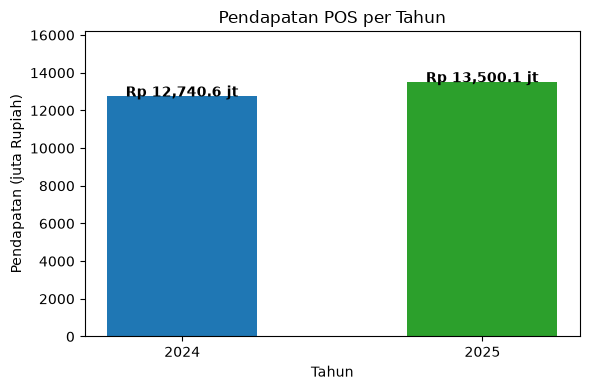

In [18]:
import matplotlib.pyplot as plt

tahun = ['2024', '2025']
nilai = [pendapatan_2024 / 1_000_000, pendapatan_2025 / 1_000_000]

plt.figure(figsize=(6, 4))
bars = plt.bar(tahun, nilai, color=['#1f77b4', '#2ca02c'], width=0.5)
plt.title('Pendapatan POS per Tahun')
plt.xlabel('Tahun')
plt.ylabel('Pendapatan (juta Rupiah)')
plt.ylim(0, max(nilai) * 1.2)
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 2, f'Rp {b.get_height():,.1f} jt',
             ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('grafik_pendapatan_per_tahun.png', dpi=150)
plt.show()